# Fibonacci spirals


In [49]:
import numpy as np
from matplotlib import pyplot as plt
import pandas as pd

from scipy.sparse import spdiags

## Tests

In [ ]:


# dimensions of the matrix
n, m = 5, 5

# create resulting matrix (init with zeros for convenience)
result = np.zeros((n, m), dtype=int)

# fill up first 2 elements of the matrix
result[0 // m][0 % m] = 0
result[1 // m][1 % m] = 1

# now you don't need to refer to the matrix but store 2 lastspdiags
# fibonacci numbers
prevprev = 0
prev = 1

for i in range(2, n * m):
    current = prevprev + prev
    result[i // m][i % m] = current
    prevprev = prev
    prev = current

# print the result
print(result)


[[    0     1     1     2     3]
 [    5     8    13    21    34]
 [   55    89   144   233   377]
 [  610   987  1597  2584  4181]
 [ 6765 10946 17711 28657 46368]]


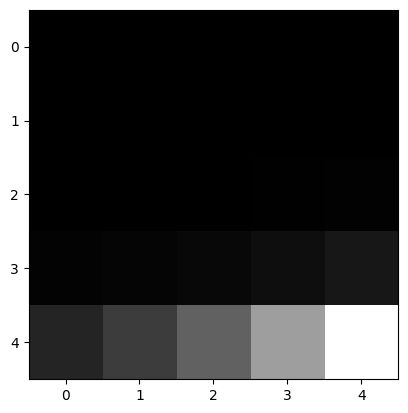

In [17]:
plt.imshow(result, cmap="gray")

# drawing a golden spiral with numpy and matplotlib

https://www.reddit.com/r/learnpython/comments/14i1y67/how_to_draw_a_golden_spiral_using_numpy_and/

In [35]:
import numpy as np    

N = 3000
full_circle = 2 * np.pi
golden = 1.61803398875

angles = np.linspace(0, full_circle * 4, num=N)
powers = angles / np.pi
radii = golden ** powers

x = np.cos(angles) * radii
y = np.sin(angles) * radii

In [45]:
print(type(x))
print(x.shape)
print(y.shape)
print(np.size(x))
# values?
unique, counts = np.unique(x, return_counts=True)
dict(zip(unique, counts))

<class 'numpy.ndarray'>
(3000,)
(3000,)
3000


{np.float64(-29.37564927203704): np.int64(1),
 np.float64(-29.375145927855137): np.int64(1),
 np.float64(-29.37404257029184): np.int64(1),
 np.float64(-29.372527149851543): np.int64(1),
 np.float64(-29.370331348170744): np.int64(1),
 np.float64(-29.367787688530086): np.int64(1),
 np.float64(-29.364521268132087): np.int64(1),
 np.float64(-29.360922433526408): np.int64(1),
 np.float64(-29.356618128783733): np.int64(1),
 np.float64(-29.35192641433359): np.int64(1),
 np.float64(-29.346627864117806): np.int64(1),
 np.float64(-29.340794801019243): np.int64(1),
 np.float64(-29.33455654273749): np.int64(1),
 np.float64(-29.32752290493461): np.int64(1),
 np.float64(-29.320410367076345): np.int64(1),
 np.float64(-29.312106179415082): np.int64(1),
 np.float64(-29.304195672609836): np.int64(1),
 np.float64(-29.294540220472523): np.int64(1),
 np.float64(-29.28591892705943): np.int64(1),
 np.float64(-29.27482076747891): np.int64(1),
 np.float64(-29.26558672958928): np.int64(1),
 np.float64(-29.25294

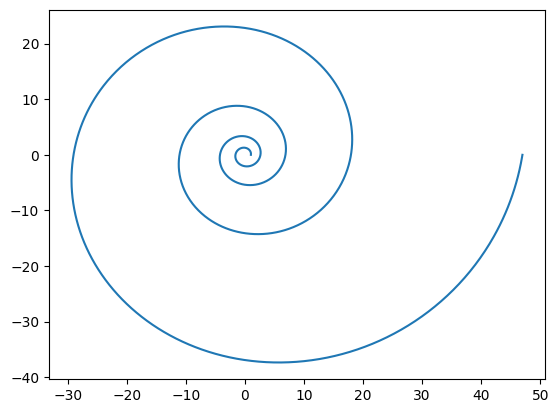

In [37]:
plt.plot(x,y)

<Axes: xlabel='x'>

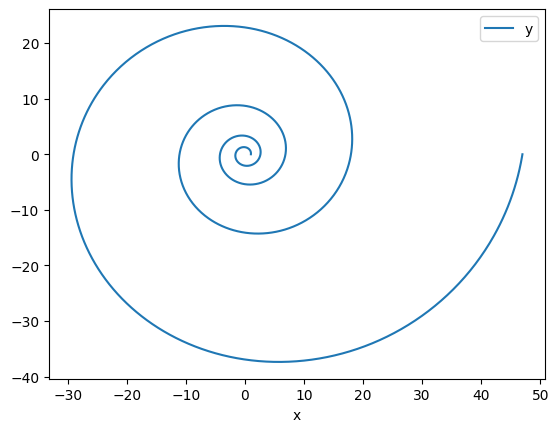

In [50]:
df = pd.DataFrame({'x':x, 'y':y})
df.plot('x', 'y')

In [53]:
# Source - https://stackoverflow.com/a
# Posted by Ricky Kim, modified by community. See post 'Timeline' for change history
# Retrieved 2026-01-26, License - CC BY-SA 4.0

num_data=len(df)
sp=spdiags(np.ones(num_data), 0, num_data,num_data)
sp


<3000x3000 sparse matrix of type '<class 'numpy.float64'>'
	with 3000 stored elements (1 diagonals) in DIAgonal format>

(3000, 3000)


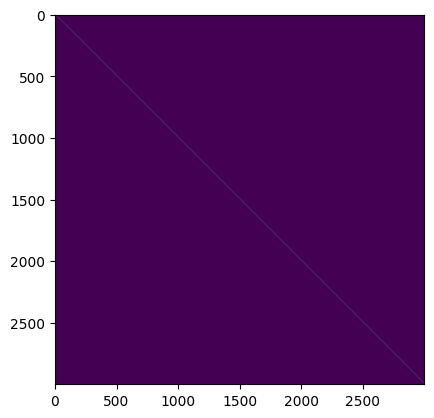

In [57]:
fibo_spiral_mask = sp.toarray()
print(fibo_spiral_mask.shape)
plt.imshow(fibo_spiral_mask)

In [30]:
fibo_spiral_array = np.column_stack(x[:], y[:])
fibo_spiral_array.shape

TypeError: column_stack() takes 1 positional argument but 2 were given

## Plotting Fibonacci Spiral with Python
https://medium.com/internet-of-technology/exploring-the-fibonacci-spiral-with-python-and-matplotlib-2dac05a0f79e

In [ ]:



def fibonacci(length: int) -> list[int]:
    """Generate Fibonacci sequence.

    :param length: The length of the Fibonacci sequence.
    :return: The Fibonacci sequence of length.
    """
    if length <= 0:
        return []

    if length == 1:
        return [0]

    sequence = [0, 1]
    while len(sequence) < length:
        next_number = sequence[-1] + sequence[-2]
        sequence.append(next_number)

    return sequence


def plot_fibonacci(sequence: list[int]) -> None:
    """Plot Fibonacci spiral.

    :param sequence: Fibonacci sequence.
    """
    # Calculate the golden ratio
    golden_ratio = sequence[-1] / sequence[-2]

    # Generate angles for the spiral
    angles = np.linspace(0, 8 * np.pi, num=len(sequence))

    # Calculate radius for logarithmic spiral
    radius = golden_ratio ** (angles / np.pi)

    # Convert to Cartesian coordinates
    x = radius * np.cos(angles)
    y = radius * np.sin(angles)

    # Create the plot
    plt.figure(figsize=(8, 8))
    plt.plot(x, y, color="blue", linewidth=2)
    plt.axis("equal")
    plt.axis("off")
    plt.show()


Fibonacci sequence of length 300 : [0, 1, 1, 2, 3, 5, 8, 13, 21, 34, 55, 89, 144, 233, 377, 610, 987, 1597, 2584, 4181, 6765, 10946, 17711, 28657, 46368, 75025, 121393, 196418, 317811, 514229, 832040, 1346269, 2178309, 3524578, 5702887, 9227465, 14930352, 24157817, 39088169, 63245986, 102334155, 165580141, 267914296, 433494437, 701408733, 1134903170, 1836311903, 2971215073, 4807526976, 7778742049, 12586269025, 20365011074, 32951280099, 53316291173, 86267571272, 139583862445, 225851433717, 365435296162, 591286729879, 956722026041, 1548008755920, 2504730781961, 4052739537881, 6557470319842, 10610209857723, 17167680177565, 27777890035288, 44945570212853, 72723460248141, 117669030460994, 190392490709135, 308061521170129, 498454011879264, 806515533049393, 1304969544928657, 2111485077978050, 3416454622906707, 5527939700884757, 8944394323791464, 14472334024676221, 23416728348467685, 37889062373143906, 61305790721611591, 99194853094755497, 160500643816367088, 259695496911122585, 42019614072748

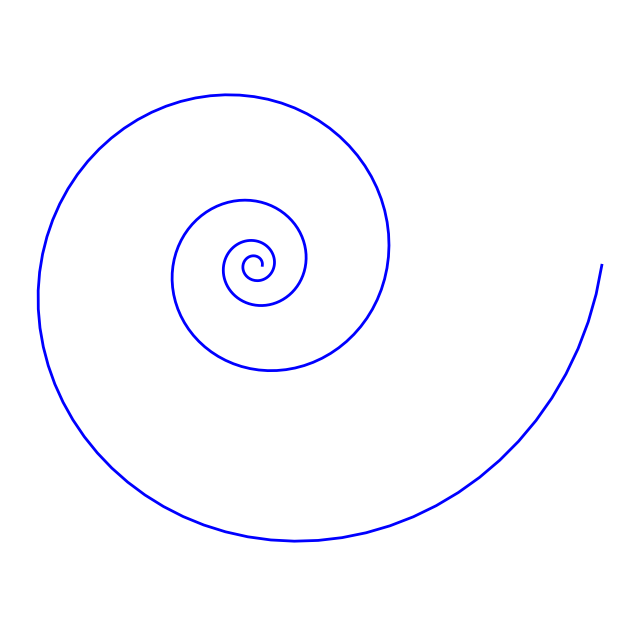

In [8]:
length = 300
sequence = fibonacci(length)
print("Fibonacci sequence of length", length, ":", sequence)
plot_fibonacci(sequence)

In [10]:

type(sequence)

list